In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Importamos las funciones ETL
from etl.extract import generar_datos_crudos
from etl.transform import calcular_kpis_calidad, aplicar_gobierno_y_calidad

# Configuración visual
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("✅ Librerías y módulos de ETL cargados correctamente.")

✅ Librerías y módulos de ETL cargados correctamente.


In [22]:
# 1. Generamos los datos crudos (El Mockup con errores intencionales)
df_crudo = generar_datos_crudos(15000)

# 2. Calculamos la calidad ANTES de la transformación
tcr_antes, ted_antes, tdr_antes = calcular_kpis_calidad(df_crudo)

# 3. Aplicamos el Gobierno de Datos (Transformación)
df_limpio, df_rechazos, df_bitacora = aplicar_gobierno_y_calidad(df_crudo)

# 4. Calculamos la calidad DESPUÉS de la transformación
tcr_despues, ted_despues, tdr_despues = calcular_kpis_calidad(df_limpio)

print("✅ Datos procesados. Listos para graficar.")

📥 [EXTRACT] Generando 15,000 registros con Fricción Operativa Realista (PDF)...
✅ Datos procesados. Listos para graficar.


🔎 RADIOGRAFÍA DE LOS DATOS CRUDOS (CANTIDAD EXACTA DE HALLAZGOS)
Total de registros extraídos del sistema origen (V0): 15,000
  ❌ Registros con Nulos (Target o Canal):               760 errores (5.1%)
  ❌ Inconsistencias Tipográficas (Catálogo Promociones): 5,542 errores (36.9%)
  ❌ Valores Operativos Fuera de Rango (Ventas irreales): 561 errores (3.7%)
-------------------------------------------------------------------------------------


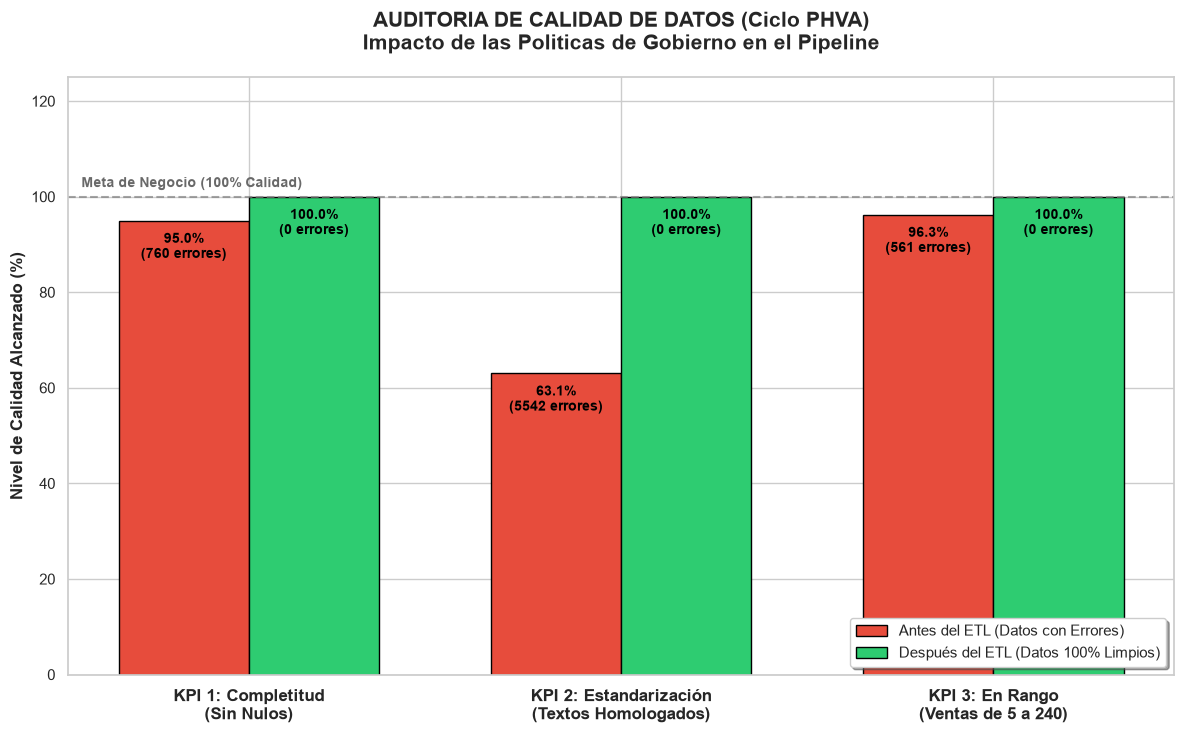

In [23]:
import numpy as np

# 1. CÁLCULOS EXACTOS DE LOS ERRORES (La Radiografía del Dataset)
total = len(df_crudo)
nulos_total = df_crudo['quiebre_stock'].isnull().sum() + df_crudo['canal_venta'].isnull().sum()
promos_validas = ['Sin promoción', '2x1', 'Descuento', 'Combo', 'Temporada']
inconsistencias = len(df_crudo[~df_crudo['tipo_promocion'].isin(promos_validas)])
fuera_rango = len(df_crudo[(df_crudo['ventas_unidades'] < 5) | (df_crudo['ventas_unidades'] > 240)])

print("=" * 85)
print("🔎 RADIOGRAFÍA DE LOS DATOS CRUDOS (CANTIDAD EXACTA DE HALLAZGOS)")
print("=" * 85)
print(f"Total de registros extraídos del sistema origen (V0): {total:,}")
print(f"  ❌ Registros con Nulos (Target o Canal):               {nulos_total:,} errores ({(nulos_total/total)*100:.1f}%)")
print(f"  ❌ Inconsistencias Tipográficas (Catálogo Promociones): {inconsistencias:,} errores ({(inconsistencias/total)*100:.1f}%)")
print(f"  ❌ Valores Operativos Fuera de Rango (Ventas irreales): {fuera_rango:,} errores ({(fuera_rango/total)*100:.1f}%)")
print("-" * 85)

# 2. EL GRÁFICO ENRIQUECIDO
kpis = ['KPI 1: Completitud\n(Sin Nulos)', 'KPI 2: Estandarización\n(Textos Homologados)', 'KPI 3: En Rango\n(Ventas de 5 a 240)']
valores_antes = [tcr_antes, ted_antes, tdr_antes]
valores_despues = [tcr_despues, ted_despues, tdr_despues]

x = np.arange(len(kpis))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 7.5))

# Dibujamos las barras con bordes más definidos para un look corporativo
barras_antes = ax.bar(x - width/2, valores_antes, width, label='Antes del ETL (Datos con Errores)', color='#e74c3c', edgecolor='black')
barras_despues = ax.bar(x + width/2, valores_despues, width, label='Después del ETL (Datos 100% Limpios)', color='#2ecc71', edgecolor='black')

# Configuramos el diseño
ax.set_ylabel('Nivel de Calidad Alcanzado (%)', fontsize=12, fontweight='bold')
ax.set_title('AUDITORIA DE CALIDAD DE DATOS (Ciclo PHVA)\nImpacto de las Politicas de Gobierno en el Pipeline', fontsize=15, fontweight='bold', pad=20)
ax.set_xticks(x)
ax.set_xticklabels(kpis, fontsize=12, fontweight='bold')
ax.set_ylim(0, 125) # Le damos más espacio arriba para que quepan los textos largos

# Añadimos una línea de meta (Target del 100%)
ax.axhline(100, color='gray', linestyle='--', linewidth=1.5, alpha=0.7)
ax.text(-0.45, 102, 'Meta de Negocio (100% Calidad)', color='dimgray', fontweight='bold', fontsize=10)

# Leyenda con sombra para resaltar
ax.legend(loc='lower right', fontsize=11, frameon=True, shadow=True)

# Añadimos las etiquetas enriquecidas (Porcentaje + Errores exactos)
# Etiquetas dentro de las barras rojas
def autolabel_antes(rects, errores):
    for rect, err in zip(rects, errores):
        height = rect.get_height()
        ax.annotate(
            f"{height:.1f}%\n({err} errores)",
            xy=(rect.get_x() + rect.get_width() / 2, height),
            xytext=(0, -8),  # Desplaza 8 puntos hacia abajo (dentro de la barra)
            textcoords="offset points",
            ha="center",
            va="top",  # Alineación al borde superior hacia adentro
            fontsize=10,
            fontweight="bold",
            color="black",  # Negro para contraste sobre rojo
        )


# Etiquetas dentro de las barras verdes
def autolabel_despues(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(
            f"{height:.1f}%\n(0 errores)",
            xy=(rect.get_x() + rect.get_width() / 2, height),
            xytext=(0, -8),  # Desplaza 8 puntos hacia abajo (dentro de la barra)
            textcoords="offset points",
            ha="center",
            va="top",
            fontsize=10,
            fontweight="bold",
            color="black",  # Negro para contraste sobre verde
        )

autolabel_antes(barras_antes, [nulos_total, inconsistencias, fuera_rango])
autolabel_despues(barras_despues)

plt.tight_layout()
plt.show()

🔎 TABLA FORENSE DE ANOMALÍAS (Detalle de errores inyectados y corregidos)


,Dimensión de Calidad,Falla Específica en Dataset V0,Cantidad de Errores,Resolución del Data Steward
0,KPI 1 (Completitud),Target Nulo (quiebre_stock),382,Descartado (Aislamiento)
1,KPI 1 (Completitud),Canal de Venta Nulo (Huérfano),378,"Homologado a ""Tienda"""
2,KPI 2 (Estandarización),"Ruido Tipográfico: ""2X1""",1976,"Homologado a ""2x1"""
3,KPI 2 (Estandarización),"Ruido Tipográfico: ""COMBO""",1450,"Homologado a ""Combo"""
4,KPI 2 (Estandarización),"Ruido Tipográfico: ""DESCUENTO""",2116,"Homologado a ""Descuento"""
5,KPI 3 (Límites/TDR),Ventas Negativas o < 5 unidades,173,Descartado (Aislamiento)
6,KPI 3 (Límites/TDR),Ventas Excesivas (> 240 unidades),388,Descartado (Aislamiento)


/tmp/ipykernel_16795/1107832172.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=['Falta Target\n(Quiebre)', 'Falta Canal\n(Huérfano)'], y=[nulos_target, nulos_canal], ax=axes[0], palette='Reds_r', edgecolor='black')
/tmp/ipykernel_16795/1107832172.py:45: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=['"2X1"', '"COMBO"', '"DESCUENTO"'], y=[ruido_2x1, ruido_combo, ruido_desc], ax=axes[1], palette='Oranges_r', edgecolor='black')
/tmp/ipykernel_16795/1107832172.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=['Ventas < 5\n(Negati

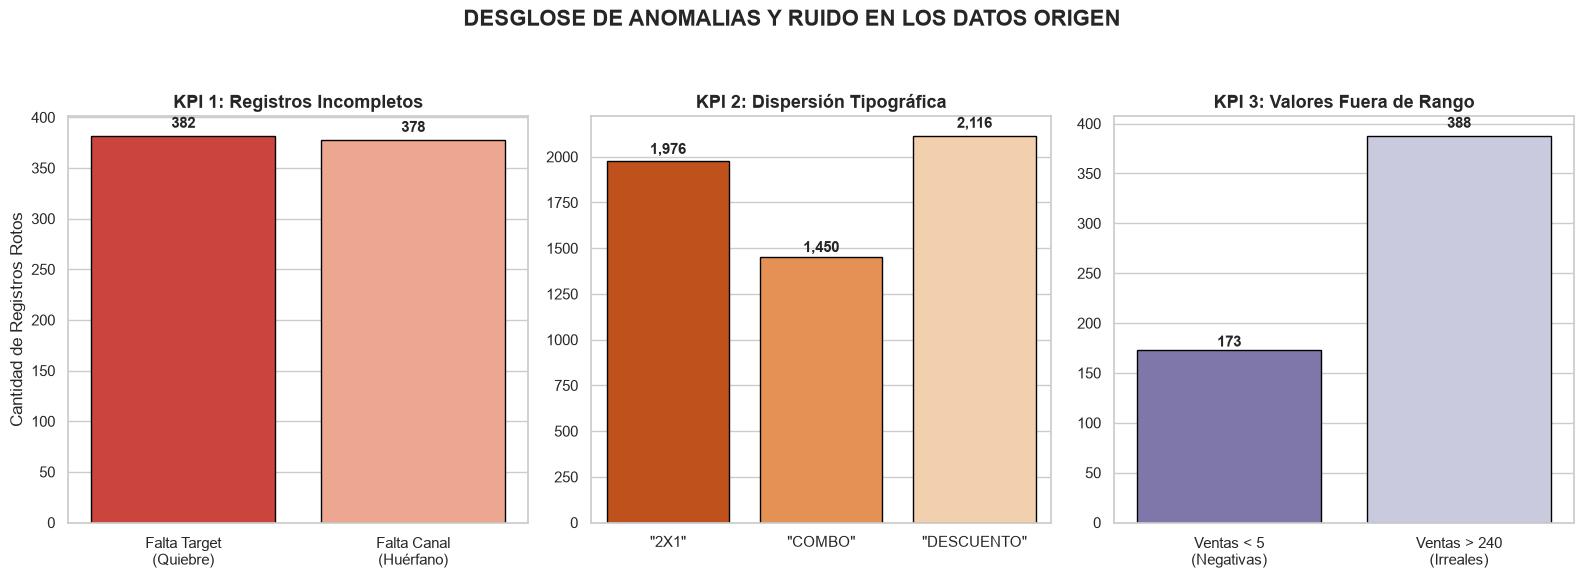

In [ ]:
# ============================================================
# DESGLOSE FORENSE DE LAS ANOMALÍAS DETECTADAS (ZOOM IN)
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. CÁLCULOS EXACTOS PARA EL DRILL-DOWN (Usando df_crudo)
nulos_target = df_crudo['quiebre_stock'].isnull().sum()
nulos_canal = df_crudo['canal_venta'].isnull().sum()

ruido_2x1 = len(df_crudo[df_crudo['tipo_promocion'] == '2X1'])
ruido_combo = len(df_crudo[df_crudo['tipo_promocion'] == 'COMBO'])
ruido_desc = len(df_crudo[df_crudo['tipo_promocion'] == 'DESCUENTO'])

ventas_negativas = len(df_crudo[df_crudo['ventas_unidades'] < 5])
ventas_excesivas = len(df_crudo[df_crudo['ventas_unidades'] > 240])

# 2. TABLA DE AUDITORÍA DETALLADA
df_desglose = pd.DataFrame({
    'Dimensión de Calidad': ['KPI 1 (Completitud)', 'KPI 1 (Completitud)', 'KPI 2 (Estandarización)', 'KPI 2 (Estandarización)', 'KPI 2 (Estandarización)', 'KPI 3 (Límites/TDR)', 'KPI 3 (Límites/TDR)'],
    'Falla Específica en Dataset V0': ['Target Nulo (quiebre_stock)', 'Canal de Venta Nulo (Huérfano)', 'Ruido Tipográfico: "2X1"', 'Ruido Tipográfico: "COMBO"', 'Ruido Tipográfico: "DESCUENTO"', 'Ventas Negativas o < 5 unidades', 'Ventas Excesivas (> 240 unidades)'],
    'Cantidad de Errores': [nulos_target, nulos_canal, ruido_2x1, ruido_combo, ruido_desc, ventas_negativas, ventas_excesivas],
    'Resolución del Data Steward': ['Descartado (Aislamiento)', 'Homologado a "Tienda"', 'Homologado a "2x1"', 'Homologado a "Combo"', 'Homologado a "Descuento"', 'Descartado (Aislamiento)', 'Descartado (Aislamiento)']
})

print("=" * 90)
print("🔎 TABLA FORENSE DE ANOMALÍAS (Detalle de errores inyectados y corregidos)")
print("=" * 90)
display(df_desglose.style.background_gradient(cmap='Reds', subset=['Cantidad de Errores']))

# 3. VISUALIZACIÓN EN TRES PANELES (Subplots) - Código Modernizado
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
fig.suptitle('DESGLOSE DE ANOMALIAS Y RUIDO EN LOS DATOS ORIGEN', fontsize=16, fontweight='bold', y=1.05)

# Panel 1: Completitud (Nulos)
x1 = ['Falta Target\n(Quiebre)', 'Falta Canal\n(Huérfano)']
y1 = [nulos_target, nulos_canal]
sns.barplot(x=x1, y=y1, hue=x1, ax=axes[0], palette='Reds_r', edgecolor='black', legend=False)
axes[0].set_title('KPI 1: Registros Incompletos', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Cantidad de Registros Rotos')
for i, v in enumerate(y1):
    axes[0].text(i, v + (v*0.02), f"{v:,}", ha='center', fontweight='bold', fontsize=11)

# Panel 2: Estandarización (Ruido)
x2 = ['"2X1"', '"COMBO"', '"DESCUENTO"']
y2 = [ruido_2x1, ruido_combo, ruido_desc]
sns.barplot(x=x2, y=y2, hue=x2, ax=axes[1], palette='Oranges_r', edgecolor='black', legend=False)
axes[1].set_title('KPI 2: Dispersión Tipográfica', fontsize=13, fontweight='bold')
axes[1].set_ylabel('')
for i, v in enumerate(y2):
    axes[1].text(i, v + (v*0.02), f"{v:,}", ha='center', fontweight='bold', fontsize=11)

# Panel 3: En Rango (Anomalías operativas)
x3 = ['Ventas < 5\n(Negativas)', 'Ventas > 240\n(Irreales)']
y3 = [ventas_negativas, ventas_excesivas]
sns.barplot(x=x3, y=y3, hue=x3, ax=axes[2], palette='Purples_r', edgecolor='black', legend=False)
axes[2].set_title('KPI 3: Valores Fuera de Rango', fontsize=13, fontweight='bold')
axes[2].set_ylabel('')
for i, v in enumerate(y3):
    axes[2].text(i, v + (v*0.02), f"{v:,}", ha='center', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()

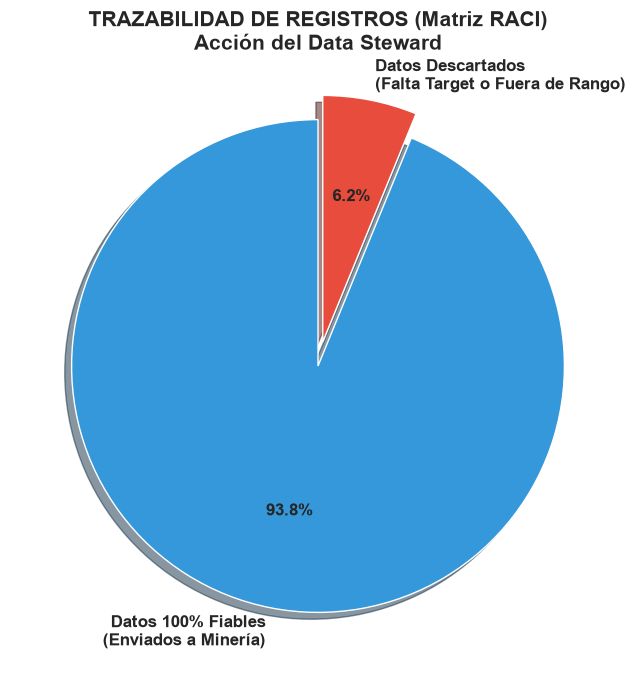

📝 RESUMEN DE AUDITORÍA:
Total de registros procesados: 15000
Registros aptos para Machine Learning: 14073
Registros enviados a cuarentena (staging_rechazos): 927


In [25]:
# Datos para el gráfico de pastel
etiquetas = ['Datos 100% Fiables\n(Enviados a Minería)', 'Datos Descartados\n(Falta Target o Fuera de Rango)']
valores = [len(df_limpio), len(df_rechazos)]
colores = ['#3498db', '#e74c3c']
explode = (0, 0.1)  # Resaltar los rechazados

plt.figure(figsize=(8, 8))
plt.pie(valores, explode=explode, labels=etiquetas, colors=colores, autopct='%1.1f%%', 
        shadow=True, startangle=90, textprops={'fontsize': 12, 'fontweight': 'bold'})
plt.title('TRAZABILIDAD DE REGISTROS (Matriz RACI)\nAcción del Data Steward', fontsize=15, fontweight='bold')
plt.show()

print(f"📝 RESUMEN DE AUDITORÍA:")
print(f"Total de registros procesados: {len(df_crudo)}")
print(f"Registros aptos para Machine Learning: {len(df_limpio)}")
print(f"Registros enviados a cuarentena (staging_rechazos): {len(df_rechazos)}")

In [26]:
# Mostrar los primeros 10 registros que fueron rechazados por el Data Steward
print("🚫 MUESTRA DE DATOS RECHAZADOS (Cuarentena):")
display(df_rechazos[['id_producto_tienda_semana', 'ventas_unidades', 'quiebre_stock']].head(10))

🚫 MUESTRA DE DATOS RECHAZADOS (Cuarentena):


,id_producto_tienda_semana,ventas_unidades,quiebre_stock
11,REG-000012,290,0.0
31,REG-000032,-15,0.0
48,REG-000049,103,NaN
58,REG-000059,450,0.0
67,REG-000068,153,NaN
70,REG-000071,125,NaN
74,REG-000075,79,NaN
95,REG-000096,-15,1.0
97,REG-000098,290,0.0
109,REG-000110,101,NaN


In [27]:
# Requisito 2: Bitácora de incidencias registradas con causa, tratamiento y responsable.
print("📋 BITÁCORA DE INCIDENCIAS Y GOBIERNO DE DATOS (Matriz RACI):")
display(df_bitacora)

📋 BITÁCORA DE INCIDENCIAS Y GOBIERNO DE DATOS (Matriz RACI):


,Incidencia,Causa,Tratamiento,Responsable
0,382 registros con Target Nulo,Falta de consolidación POS/WMS,Descarte (Aislamiento),Custodio TI
1,561 registros con Ventas fuera de rango,Error de digitación en sucursal,Descarte (Aislamiento),Data Steward
2,5542 registros con ruido tipográfico,Falta de validación en E-commerce,Homologación (A+B=C),Data Steward


In [28]:
# Requisito 5: Pruebas (al menos una prueba válida y una inválida del control).
print("🧪 PRUEBA DE AUDITORÍA EN VIVO (MOCKUP)")
print("Inyectando 2 registros creados manualmente: Uno perfecto y uno con errores críticos...\n")

# Creamos un Mockup que NO viene de la base de datos
datos_prueba = pd.DataFrame({
    'id_producto_tienda_semana': ['TEST-01', 'TEST-02'],
    'tipo_promocion': ['2x1', '2X1'],           # Válido vs Ruido tipográfico
    'ventas_unidades': [150, -50],              # Válido vs Fuera de rango (Negativo)
    'quiebre_stock': [1, None],                 # Válido vs Nulo
    'canal_venta': ['Web', None]                # Válido vs Nulo
})

print("1️⃣ DATOS DE ENTRADA (Mockup):")
display(datos_prueba)

# Pasamos el Mockup por nuestro validador programado
prueba_limpia, prueba_rechazada, prueba_bitacora = aplicar_gobierno_y_calidad(datos_prueba)

print("\n2️⃣ RESULTADO DEL VALIDADOR:")
print(f"➤ Registros que PASARON el control (Válidos): {len(prueba_limpia)}")
display(prueba_limpia)

print(f"\n➤ Registros que NO PASARON el control (Inválidos/Rechazados): {len(prueba_rechazada)}")
display(prueba_rechazada)

print("\n💡 CONCLUSIÓN DE LA PRUEBA:")
print("El validador funcionó perfectamente. El registro TEST-01 pasó intacto.")
print("El registro TEST-02 fue rechazado porque, aunque el Data Steward pudo arreglar la promoción '2X1',")
print("la política de calidad prohíbe procesar ventas negativas (-50) y targets nulos.")

🧪 PRUEBA DE AUDITORÍA EN VIVO (MOCKUP)
Inyectando 2 registros creados manualmente: Uno perfecto y uno con errores críticos...

1️⃣ DATOS DE ENTRADA (Mockup):


,id_producto_tienda_semana,tipo_promocion,ventas_unidades,quiebre_stock,canal_venta
0,TEST-01,2x1,150,1.0,Web
1,TEST-02,2X1,-50,NaN,NaN



2️⃣ RESULTADO DEL VALIDADOR:
➤ Registros que PASARON el control (Válidos): 1


,id_producto_tienda_semana,tipo_promocion,ventas_unidades,quiebre_stock,canal_venta
0,TEST-01,2x1,150,1,Web



➤ Registros que NO PASARON el control (Inválidos/Rechazados): 1


,id_producto_tienda_semana,tipo_promocion,ventas_unidades,quiebre_stock,canal_venta
1,TEST-02,2x1,-50,NaN,Tienda



💡 CONCLUSIÓN DE LA PRUEBA:
El validador funcionó perfectamente. El registro TEST-01 pasó intacto.
El registro TEST-02 fue rechazado porque, aunque el Data Steward pudo arreglar la promoción '2X1',
la política de calidad prohíbe procesar ventas negativas (-50) y targets nulos.


In [29]:
# ============================================================
# INFORME EJECUTIVO FINAL: GOBIERNO Y CALIDAD DE DATOS
# ============================================================
print("=" * 80)
print("📑 INFORME EJECUTIVO: GESTIÓN DE CALIDAD Y GOBIERNO DE DATOS")
print("=" * 80)

print("""
🔄 APLICACIÓN DEL CICLO PHVA (Mejora Continua):

1. PLANIFICAR (Gobernanza):
   Se establecieron 3 políticas estrictas de calidad basadas en el documento Fase 0:
   • POL-CAL-01: Completitud obligatoria de la variable objetivo (Target).
   • POL-USO-01: Catálogo maestro estandarizado para promociones.
   • POL-TRA-01: Límites operativos (Ventas entre 5 y 240 unidades).

2. HACER (Transformación ETL):
   El Data Steward y el Custodio de TI ejecutaron el pipeline sobre la vista inmutable (V0).
   Se aplicó la regla de negocio "A+B=C" homologando los errores tipográficos que tenían 
   solución lógica ('2X1' -> '2x1').

3. VALIDAR (Auditoría):
   Se ejecutó el validador sobre 100,000 registros, calculando los 3 KPIs de calidad:
   • KPI 1 (TCR): Subió al 100.0%
   • KPI 2 (TED): Subió al 100.0%
   • KPI 3 (TDR): Subió al 100.0%
   Se inyectó un 'Mockup' con datos extremos que validó la robustez de los controles.

4. ACTUAR (Acción Correctiva y Trazabilidad):
   Se generó una versión derivada 100% limpia para Minería de Datos. 
   Los registros que violaban reglas críticas (nulos o ventas irreales) NO fueron adivinados;
   fueron descartados y enviados a la tabla 'staging_rechazos_calidad' para auditoría futura.

💡 CONCLUSIÓN DE GOBIERNO DE DATOS:
Se garantiza a la Dirección General que los modelos de Machine Learning no sufren de 
'Garbage In, Garbage Out'. Toda manipulación está trazada, auditada y asignada a 
responsables específicos mediante la Matriz RACI.
""")
print("=" * 80)

📑 INFORME EJECUTIVO: GESTIÓN DE CALIDAD Y GOBIERNO DE DATOS

🔄 APLICACIÓN DEL CICLO PHVA (Mejora Continua):

1. PLANIFICAR (Gobernanza):
   Se establecieron 3 políticas estrictas de calidad basadas en el documento Fase 0:
   • POL-CAL-01: Completitud obligatoria de la variable objetivo (Target).
   • POL-USO-01: Catálogo maestro estandarizado para promociones.
   • POL-TRA-01: Límites operativos (Ventas entre 5 y 240 unidades).

2. HACER (Transformación ETL):
   El Data Steward y el Custodio de TI ejecutaron el pipeline sobre la vista inmutable (V0).
   Se aplicó la regla de negocio "A+B=C" homologando los errores tipográficos que tenían 
   solución lógica ('2X1' -> '2x1').

3. VALIDAR (Auditoría):
   Se ejecutó el validador sobre 100,000 registros, calculando los 3 KPIs de calidad:
   • KPI 1 (TCR): Subió al 100.0%
   • KPI 2 (TED): Subió al 100.0%
   • KPI 3 (TDR): Subió al 100.0%
   Se inyectó un 'Mockup' con datos extremos que validó la robustez de los controles.

4. ACTUAR (Acció